## Agenda


1. Environment & API Setup
2. Generation Models vs Reasoning Models
3. Base vs Instruct vs Chat Models
4. Chat Templates
5. Decoding & Generation Strategies


## Part 1: Environment Setup

* Required packages are installed for all three providers.
* API keys are configured via environment variables.
* Clients are initialized for OpenAI, Anthropic, and HuggingFace.

In [1]:
!pip install openai anthropic huggingface_hub transformers accelerate pydantic tenacity torch -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 837.5/837.5 kB 13.9 MB/s eta 0:00:00


In [2]:
import os
import getpass

In [ ]:
key = "OPENAI_API_KEY"

In [4]:
# Configure API keys from Colab Secrets
os.environ["OPENAI_API_KEY"] = key

In [8]:
from huggingface_hub import login
login()

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


In [ ]:
#token = "OPENAI_API_KEY"

In [6]:
# Initialize clients
from openai import OpenAI
import anthropic

openai_client = OpenAI()  # Reads OPENAI_API_KEY automatically
#anthropic_client = anthropic.Anthropic()  # Reads ANTHROPIC_API_KEY automatically

print("✅ Clients initialized successfully!")

✅ Clients initialized successfully!


### 2. Generation Models vs Reasoning Models

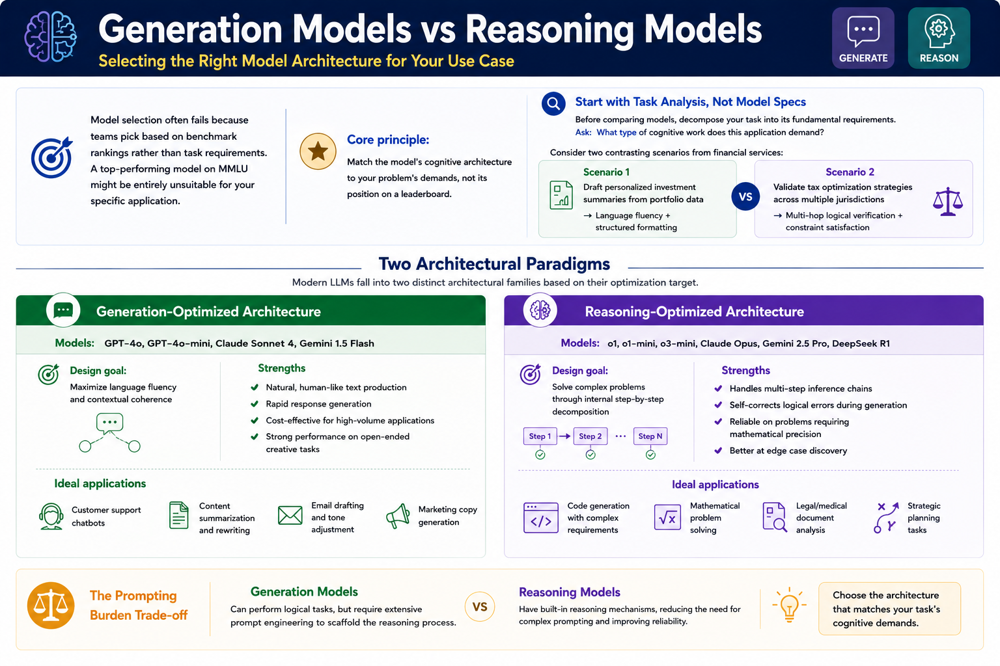

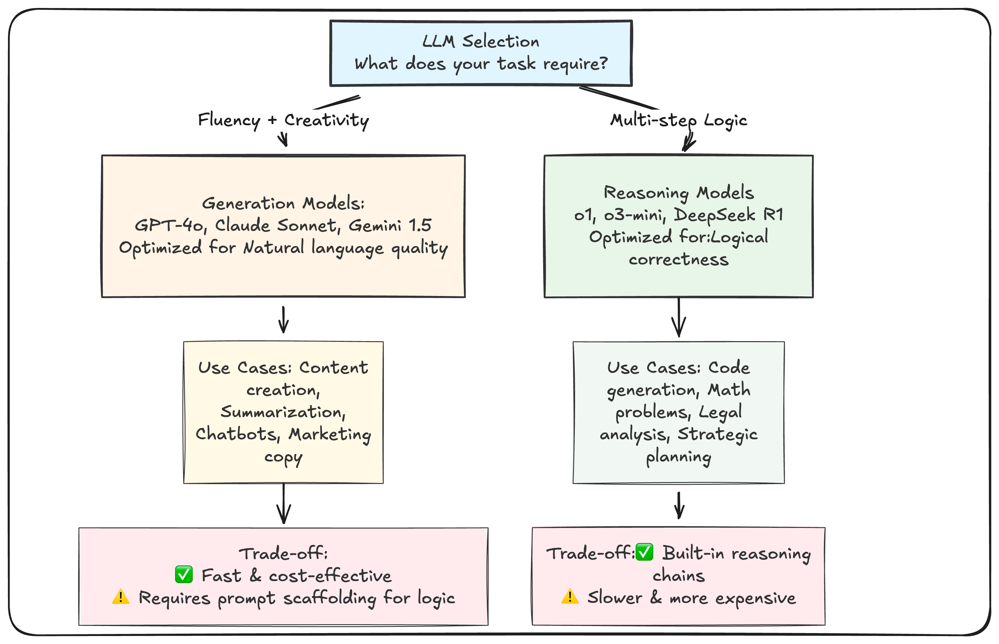

In [9]:
# ============================================================
# Demonstration: Loan Approval Decision Using Different
# LLM Architectures
#
# This example compares:
#
# 1. GPT-4o-mini  -> Generation-focused model
#    - Requires explicit reasoning steps in the prompt
#    - Prompt engineer designs the thinking structure
#
# 2. o1-mini -> Reasoning-focused model
#    - Performs internal reasoning automatically
#    - Prompt engineer mainly defines objectives + constraints
#
# Purpose:
# Show how prompting strategy changes depending on the
# architecture of the model being used.
# ============================================================

from openai import OpenAI

# ------------------------------------------------------------
# Initialize OpenAI client
# ------------------------------------------------------------
client = OpenAI()


# ============================================================
# APPROACH 1:
# GENERATION MODEL (GPT-4o-mini)
# ============================================================

def loan_decision_with_generation_model(applicant_data):
    """
    Loan approval using a GENERATION-ORIENTED model.

    Key Idea:
    ----------
    Generation models work best when the reasoning process
    is explicitly broken into steps.

    Here we:
    - Define each evaluation stage manually
    - Ask the model to fill intermediate calculations
    - Control the reasoning structure via prompt engineering

    This approach is similar to:
    - Chain-of-thought scaffolding
    - Guided reasoning
    - Structured prompting
    """

    # --------------------------------------------------------
    # Structured prompt with explicit reasoning instructions
    # --------------------------------------------------------
    structured_prompt = f"""
You are evaluating a loan application.

Follow these EXACT steps carefully.

--------------------------------------------------
STEP 1 - Compute Debt-to-Income Ratio (DTI)
--------------------------------------------------
Monthly debt: ${applicant_data['debt']}
Monthly income: ${applicant_data['income']}

Formula:
DTI = debt ÷ income

Your calculation: _____


--------------------------------------------------
STEP 2 - Classify Credit Tier
--------------------------------------------------
Credit score: {applicant_data['credit_score']}

Credit Tiers:
- 740+      : Premium
- 670 - 739 : Standard
- 580 - 669 : Subprime
- Below 580 : High-risk

Classification: _____


--------------------------------------------------
STEP 3 - Verify Employment Stability
--------------------------------------------------
Months employed: {applicant_data['employment_months']}
Minimum required: 24 months

Income variance: {applicant_data['income_variance']}%
Maximum allowed: 15%

Employment status: _____


--------------------------------------------------
STEP 4 - Assess Collateral Coverage
--------------------------------------------------
Property value: ${applicant_data['collateral']}
Loan amount: ${applicant_data['loan_amount']}

Calculate:
Loan-to-Value (LTV) ratio = loan_amount ÷ collateral

LTV ratio: _____


--------------------------------------------------
FINAL DECISION
--------------------------------------------------
Based on all previous evaluations:

Output:
- Approved OR Denied
- Provide justification for the decision
"""

    # --------------------------------------------------------
    # Call GPT-4o-mini
    #
    # temperature = 0
    # -> Makes output deterministic and consistent
    # -> Important for business-rule evaluations
    # --------------------------------------------------------
    response = client.chat.completions.create(
        model="gpt-4o-mini",
        messages=[
            {
                "role": "user",
                "content": structured_prompt
            }
        ],
        temperature=0
    )

    # Extract generated response text
    return response.choices[0].message.content


# ============================================================
# APPROACH 2:
# REASONING MODEL (o1-mini)
# ============================================================

def loan_decision_with_reasoning_model(applicant_data):
    """
    Loan approval using a REASONING-ORIENTED model.

    Key Idea:
    ----------
    Reasoning models internally decompose problems.

    Instead of explicitly defining:
    - calculations
    - intermediate steps
    - reasoning workflow

    We only provide:
    - business rules
    - constraints
    - objective

    The model performs the reasoning internally.
    """

    # --------------------------------------------------------
    # Minimal prompt
    #
    # Notice:
    # - No forced step-by-step reasoning
    # - No explicit decomposition
    # - Just goals + constraints
    # --------------------------------------------------------
    minimal_prompt = f"""
Evaluate this loan application against our approval criteria.

--------------------------------------------------
APPLICANT DATA
--------------------------------------------------
- Monthly debt: ${applicant_data['debt']}
- Monthly income: ${applicant_data['income']}
- Credit score: {applicant_data['credit_score']}
- Employment duration: {applicant_data['employment_months']} months
- Income variance: {applicant_data['income_variance']}%
- Collateral value: ${applicant_data['collateral']}
- Requested loan amount: ${applicant_data['loan_amount']}

--------------------------------------------------
APPROVAL CRITERIA
--------------------------------------------------
- Debt-to-income ratio must be below 43%
- Credit score must be at least 580
- Employment duration must be >= 24 months
- Income variance must be below 15%
- Collateral must adequately cover the loan

--------------------------------------------------
TASK
--------------------------------------------------
Decide whether the loan should be approved or denied.

Explain your reasoning clearly.
"""

    # --------------------------------------------------------
    # Call reasoning model
    #
    # No temperature specified:
    # reasoning models are generally optimized for
    # deliberate and structured outputs already.
    # --------------------------------------------------------
    response = client.chat.completions.create(
        model="o1-mini",
        messages=[
            {
                "role": "user",
                "content": minimal_prompt
            }
        ]
    )

    # Extract generated response text
    return response.choices[0].message.content


# ============================================================
# SAMPLE INPUT DATA
# ============================================================

test_application = {
    "debt": 2800,
    "income": 7500,
    "credit_score": 695,
    "employment_months": 30,
    "income_variance": 12.5,
    "collateral": 180000,
    "loan_amount": 140000
}


# ============================================================
# ARCHITECTURE COMPARISON SUMMARY
# ============================================================

print("=" * 70)
print("GENERATION MODEL (GPT-4o-mini)")
print("=" * 70)

print("Prompt strategy : Explicit step-by-step scaffolding")
print("Engineer's role : Design the reasoning workflow")
print("Strength         : Lower cost + controllable outputs")
print("Weakness         : Requires careful prompt engineering")

print()


print("=" * 70)
print("REASONING MODEL (o1-mini)")
print("=" * 70)

print("Prompt strategy : Define goals + constraints only")
print("Engineer's role : Define success criteria")
print("Strength         : Better autonomous reasoning")
print("Weakness         : Higher token/computation cost")

print("=" * 70)


# ============================================================
# OPTIONAL EXECUTION
# ============================================================
# Uncomment to test both models
# ============================================================

# print("\n\n--- GPT-4o-mini Result ---")
# print(loan_decision_with_generation_model(test_application))

# print("\n\n--- o1-mini Result ---")
# print(loan_decision_with_reasoning_model(test_application))

GENERATION MODEL (GPT-4o-mini)
Prompt strategy : Explicit step-by-step scaffolding
Engineer's role : Design the reasoning workflow
Strength         : Lower cost + controllable outputs
Weakness         : Requires careful prompt engineering

REASONING MODEL (o1-mini)
Prompt strategy : Define goals + constraints only
Engineer's role : Define success criteria
Strength         : Better autonomous reasoning
Weakness         : Higher token/computation cost


## Part2: Understanding Model Types

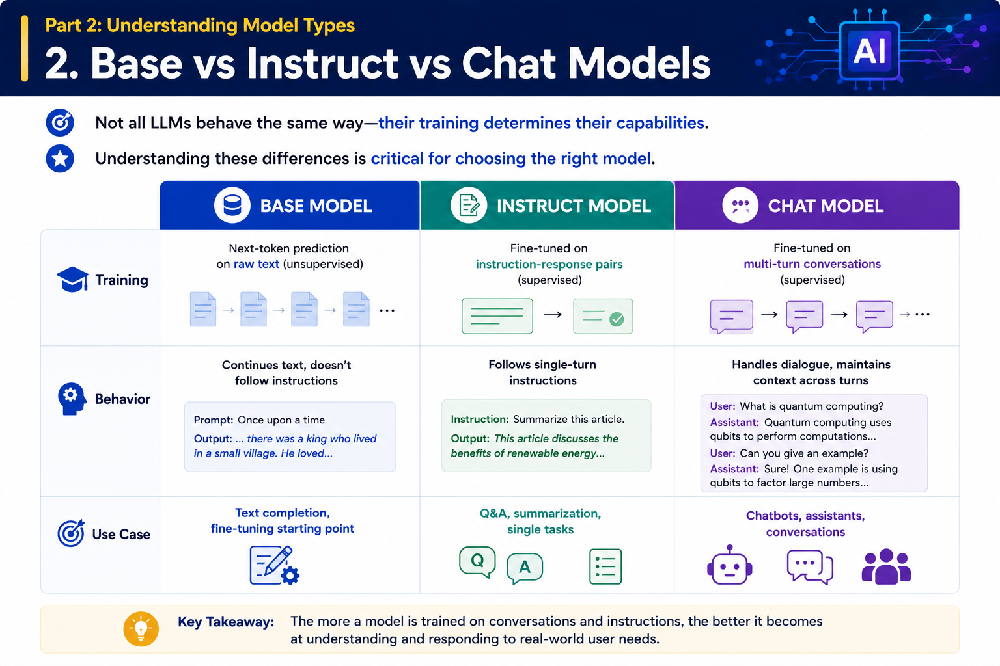

---

### 3. Base Model Behavior

- Base models are trained purely on **next-token prediction**.
- They don't understand "instructions"—they just continue the text.
- Think of them as autocomplete on steroids.


In [10]:
# ============================================================
# DEMONSTRATION:
# Text Generation Using a Base Causal Language Model
#
# Model Used:
# - GPT-2 (decoder-only transformer)
#
# Objective:
# - Show how a base language model generates text
# - Demonstrate tokenization + inference workflow
# - Explain generation parameters clearly
#
# Key Learning:
# Base models are NOT instruction-tuned.
# They continue text based on learned patterns.
#
# Example:
# Prompt:
#   "What is the capital of France?"
#
# The model does NOT truly "answer" like ChatGPT.
# It simply predicts the next most probable tokens.
# ============================================================


# ============================================================
# IMPORT REQUIRED LIBRARIES
# ============================================================

from transformers import AutoModelForCausalLM, AutoTokenizer
import torch


# ============================================================
# STEP 1: LOAD PRETRAINED MODEL + TOKENIZER
# ============================================================

# ------------------------------------------------------------
# GPT-2 is a decoder-only transformer model
#
# AutoTokenizer:
#   Converts text -> tokens (numerical IDs)
#
# AutoModelForCausalLM:
#   Loads a causal language model capable of:
#   - next token prediction
#   - text generation
# ------------------------------------------------------------

model_name = "gpt2"

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(model_name)

# Load pretrained GPT-2 model
model = AutoModelForCausalLM.from_pretrained(model_name)


# ============================================================
# STEP 2: DEFINE INPUT PROMPT
# ============================================================

# ------------------------------------------------------------
# This is the starting text given to the model.
#
# GPT-2 will continue generating text from this prompt.
# ------------------------------------------------------------

prompt = "What is the capital of France?"


# ============================================================
# STEP 3: TOKENIZE INPUT TEXT
# ============================================================

# ------------------------------------------------------------
# Tokenization converts human-readable text into tensors.
#
# Example:
# "Hello world"
#   -> [15496, 995]
#
# return_tensors="pt"
#   -> Returns PyTorch tensor format
# ------------------------------------------------------------

input_ids = tokenizer.encode(
    prompt,
    return_tensors="pt"
)


# ============================================================
# STEP 4: GENERATE TEXT
# ============================================================

# ------------------------------------------------------------
# model.generate() performs autoregressive generation.
#
# Workflow:
#   1. Predict next token
#   2. Append predicted token
#   3. Feed updated sequence back into model
#   4. Repeat until stopping condition
# ------------------------------------------------------------

output = model.generate(

    # Input token IDs
    input_ids,

    # Maximum number of NEW tokens to generate
    max_new_tokens=50,

    # Enable probabilistic sampling
    # instead of greedy decoding
    do_sample=True,

    # Controls randomness:
    #
    # Lower temperature:
    #   -> safer / more deterministic
    #
    # Higher temperature:
    #   -> more creative / random
    temperature=0.7,

    # GPT-2 does not have an official padding token
    # so EOS token is reused
    pad_token_id=tokenizer.eos_token_id
)


# ============================================================
# STEP 5: DECODE OUTPUT TOKENS BACK TO TEXT
# ============================================================

# ------------------------------------------------------------
# Convert generated token IDs back into readable text
#
# skip_special_tokens=True
#   -> Removes tokens like <EOS>
# ------------------------------------------------------------

generated_text = tokenizer.decode(
    output[0],
    skip_special_tokens=True
)


# ============================================================
# STEP 6: DISPLAY RESULT
# ============================================================

print("=" * 70)
print("INPUT PROMPT")
print("=" * 70)
print(prompt)

print("\n")

print("=" * 70)
print("GENERATED OUTPUT")
print("=" * 70)
print(generated_text)


# ============================================================
# IMPORTANT CONCEPTS
# ============================================================

# 1. CAUSAL LANGUAGE MODEL
# ------------------------------------------------------------
# GPT-2 predicts the NEXT token using PREVIOUS tokens only.
#
# Example:
# Input:
#   "The capital of France is"
#
# Model predicts:
#   "Paris"
#
# This is called:
#   Left-to-right autoregressive generation
# ------------------------------------------------------------


# 2. BASE MODEL vs INSTRUCTION-TUNED MODEL
# ------------------------------------------------------------
# GPT-2 is a BASE MODEL.
#
# It was trained to:
#   Continue text
#
# It was NOT specifically trained to:
#   - follow instructions
#   - answer safely
#   - behave like a chatbot
#
# ChatGPT-style models are:
#   - instruction tuned
#   - RLHF aligned
# ------------------------------------------------------------


# 3. TEMPERATURE
# ------------------------------------------------------------
# Controls probability distribution sharpness.
#
# Low temperature (0.2):
#   More deterministic
#
# High temperature (1.2):
#   More random
# ------------------------------------------------------------


# 4. SAMPLING
# ------------------------------------------------------------
# do_sample=True:
#   Randomly samples from probability distribution
#
# do_sample=False:
#   Greedy decoding (always highest probability token)
# ------------------------------------------------------------


# 5. max_new_tokens
# ------------------------------------------------------------
# Limits generation length.
#
# Prevents infinite or extremely long outputs.
# ------------------------------------------------------------

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2LMHeadModel LOAD REPORT from: gpt2
Key                  | Status     |  | 
---------------------+------------+--+-
h.{0...11}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

The attention mask is not set and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.


INPUT PROMPT
What is the capital of France?


GENERATED OUTPUT
What is the capital of France?

The capital of France is Paris (French: Paris).

French capital: Paris is the number eight capital.

Capital of France: Paris is the number one capital.

Capital of France: Paris is the number two capital


- **Observation:**  
  The base model doesn't "answer" the question.

- It continues the text as if it's completing a document or article.

- Sometimes it gets lucky and includes the answer, but it's not reliably following instructions.

#### More Examples of Base Model Behavior


In [11]:
prompts = [
    "Translate 'Hello' to French:",
    "Write a poem about the ocean:",
    "Summarize the following: The quick brown fox jumps over the lazy dog.",
    "Answer the following question: What is 2+2?",
]

for prompt in prompts:
    input_ids = tokenizer.encode(prompt, return_tensors="pt")
    output = model.generate(
        input_ids,
        max_new_tokens=30,
        do_sample=True,
        temperature=0.7,
        pad_token_id=tokenizer.eos_token_id
    )
    print(f"Prompt: {prompt}")
    print(f"Output: {tokenizer.decode(output[0], skip_special_tokens=True)}\n")
    print('-'*50)

Prompt: Translate 'Hello' to French:
Output: Translate 'Hello' to French:

"Hello, hello, hello!"

"Hello, hello, hello!"

It's a great gesture to have, but the

--------------------------------------------------
Prompt: Write a poem about the ocean:
Output: Write a poem about the ocean:

I am a sea star, and sea is my land: and I am a sea man

I am a sea man

I

--------------------------------------------------
Prompt: Summarize the following: The quick brown fox jumps over the lazy dog.
Output: Summarize the following: The quick brown fox jumps over the lazy dog.

The quick brown fox jumps over the lazy dog. The quick brown fox has an easy time with the dog.

The quick brown fox

--------------------------------------------------
Prompt: Answer the following question: What is 2+2?
Output: Answer the following question: What is 2+2?

Answer the following question: What is 2+2?

Answer the following question: What is 2+2?

Answer the

--------------------------------------------------

- Base models often:
  - Continue with more examples of the same pattern
  - Repeat the input
  - Generate quiz-like formats instead of direct answers
  - Don't know when to stop

---

### Instruct Model Behavior

- Instruct models are **fine-tuned** on (instruction, response) pairs.
- They understand that a prompt is a request to perform a task.
- They generate appropriate responses rather than continuations.


In [12]:
from transformers import pipeline
import torch

# Load an instruct model
model_name = "TinyLlama/TinyLlama-1.1B-Chat-v1.0"
generator = pipeline(
    "text-generation",
    model=model_name,
    dtype=torch.float16,
    device_map="auto"
)

# Same prompt as before - using instruction format
prompt = "What is the capital of France?"
formatted_prompt = f"<|user|>\n{prompt}</s>\n<|assistant|>\n"

output = generator(
    formatted_prompt,
    max_new_tokens=50,
    do_sample=True,
    temperature=0.7,
)

config.json:   0%|          | 0.00/608 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/2.20G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.29k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.84M [00:00<?, ?B/s]

tokenizer.model:   0%|          | 0.00/500k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/551 [00:00<?, ?B/s]

Passing `generation_config` together with generation-related arguments=({'max_new_tokens', 'do_sample', 'temperature'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
Both `max_new_tokens` (=50) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


In [13]:
print("Prompt:", prompt)

Prompt: What is the capital of France?


In [14]:
print("Instruct Model Output:", output[0]['generated_text'].split("<|assistant|>")[-1].strip())

Instruct Model Output: The capital of France is Paris.


- **Observation:**  
  The instruct model directly answers the question!

- It understands the prompt is an instruction, not text to continue.



---

### Chat Model Behavior

* Chat models handle **multi-turn conversations**
 and maintain context.

In [15]:
# Multi-turn conversation demonstration
messages = [
    {"role": "system", "content": "You are a helpful math tutor."},
    {"role": "user", "content": "What is 5 + 3?"},
]

# First turn
output = generator(messages, max_new_tokens=50)
assistant_response = output[0]['generated_text'][-1]['content']
print(f"User: What is 5 + 3?")
print(f"Assistant: {assistant_response}\n")

# Add assistant response to history
messages.append({"role": "assistant", "content": assistant_response})

# Second turn - referring to previous context
messages.append({"role": "user", "content": "Now multiply that result by 2."})
output = generator(messages, max_new_tokens=50)
assistant_response = output[0]['generated_text'][-1]['content']
print(f"User: Now multiply that result by 2.")
print(f"Assistant: {assistant_response}\n")

# Third turn
messages.append({"role": "assistant", "content": assistant_response})
messages.append({"role": "user", "content": "What if I divide that by 4?"})
output = generator(messages, max_new_tokens=50)
assistant_response = output[0]['generated_text'][-1]['content']
print(f"User: What if I divide that by 4?")
print(f"Assistant: {assistant_response}")

Passing `generation_config` together with generation-related arguments=({'max_new_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
Both `max_new_tokens` (=50) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=50) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


User: What is 5 + 3?
Assistant: 5 + 3 = 8



Both `max_new_tokens` (=50) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


User: Now multiply that result by 2.
Assistant: 5 × 2 = 10

Now, 10 + 3 = 13, and finally:

13 = 13

So, the final answer is 13.

User: What if I divide that by 4?
Assistant: To find the quotient (the remainder when 5 is divided by 4), we divide both sides of the expression by 4:

5 / 4 = 1

The quotient (1) is multiplied by 


- **Key observation:**  
  The chat model understands "that result" and "that" refer to previous answers!

- Base models would fail at this because they don't understand conversational context.

---

### Summary Code

In [17]:
from transformers import AutoModelForCausalLM, AutoTokenizer, pipeline
import torch

# ============================================================
# SETUP: Load all three model types
# ============================================================

# 1. Base Model (GPT-2)
base_tokenizer = AutoTokenizer.from_pretrained("gpt2")
base_model = AutoModelForCausalLM.from_pretrained("gpt2")

# 2. Instruct/Chat Model
chat_pipe = pipeline(
    "text-generation",
    model="TinyLlama/TinyLlama-1.1B-Chat-v1.0",
    torch_dtype=torch.float16,
    device_map="auto"
)

def generate_base(prompt, max_tokens=50):
    """Generate with base model (raw text continuation)"""
    inputs = base_tokenizer.encode(prompt, return_tensors="pt")
    outputs = base_model.generate(
        inputs,
        max_new_tokens=max_tokens,
        do_sample=True,
        temperature=0.7,
        pad_token_id=base_tokenizer.eos_token_id
    )
    full_output = base_tokenizer.decode(outputs[0], skip_special_tokens=True)
    return full_output[len(prompt):].strip()

def generate_instruct(prompt, max_tokens=50):
    """Generate with instruct format"""
    formatted = f"<|user|>\n{prompt}</s>\n<|assistant|>\n"
    output = chat_pipe(formatted, max_new_tokens=max_tokens, do_sample=True, temperature=0.7)
    return output[0]['generated_text'].split("<|assistant|>")[-1].strip()

def generate_chat(messages, max_tokens=50):
    """Generate with chat format"""
    output = chat_pipe(messages, max_new_tokens=max_tokens)
    return output[0]['generated_text'][-1]['content'].strip()

# ============================================================
# TEST: Same prompts, different model types
# ============================================================

test_cases = [
    {"name": "Simple Question", "prompt": "What is the capital of Japan?"},
    {"name": "Instruction", "prompt": "List 3 benefits of exercise."},
    {"name": "Creative Task", "prompt": "Write a short poem about rain."},
    {"name": "Reasoning", "prompt": "If a train travels 60 mph for 2 hours, how far does it go?"},
]

for test in test_cases:
    prompt = test["prompt"]
    print("=" * 70)
    print(f"TEST: {test['name']}")
    print(f"PROMPT: {prompt}")
    print("=" * 70)

    # Base model
    base_output = generate_base(prompt)
    print(f"\n🔵 BASE MODEL (GPT-2):")
    print(f"   {base_output[:150]}...")

    # Instruct model
    instruct_output = generate_instruct(prompt)
    print(f"\n🟢 INSTRUCT MODEL:")
    print(f"   {instruct_output[:150]}")

    # Chat model
    chat_messages = [
        {"role": "system", "content": "You are a helpful assistant."},
        {"role": "user", "content": prompt}
    ]
    chat_output = generate_chat(chat_messages)
    print(f"\n🟣 CHAT MODEL:")
    print(f"   {chat_output[:150]}")
    print("\n")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2LMHeadModel LOAD REPORT from: gpt2
Key                  | Status     |  | 
---------------------+------------+--+-
h.{0...11}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

TEST: Simple Question
PROMPT: What is the capital of Japan?


Both `max_new_tokens` (=50) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


...


🟢 INSTRUCT MODEL:
   Amidst the gray skies and misty damp,
A rainbow blooms, a sight to behold,
A rainbow, a symbol of hope and change,
The storm has passed, and the rain 

🟣 CHAT MODEL:
   Rain, gentle and melodious,
Birds soar and sing out,
A symphony in the air,
A dance of light and dark.

The world slows, its pace soft,
As rain falls


TEST: Reasoning
PROMPT: If a train travels 60 mph for 2 hours, how far does it go?


Both `max_new_tokens` (=50) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



🔵 BASE MODEL (GPT-2):
   This question is often answered by asking if trains are not moving at that speed and not moving at the same time. In this case, the answer is no. The ...


Both `max_new_tokens` (=50) and `max_length`(=2048) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



🟢 INSTRUCT MODEL:
   The train travels 60 mph for 2 hours. So, to determine how far it goes, we divide 60 mph by 2 hours:

60 mph divided by 2 hours = 30

🟣 CHAT MODEL:
   A train traveling at a speed of 60 mph for 2 hours has traveled a distance of 120 miles (200 kilometers). Let's convert miles to kilometers: 120 miles




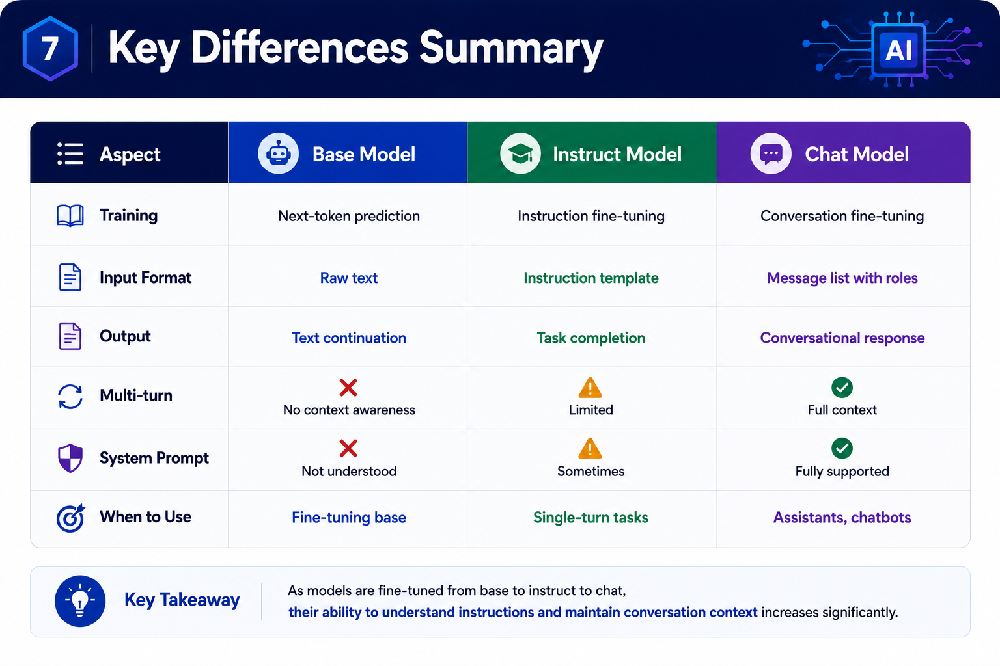

### Choosing the Right Model Type

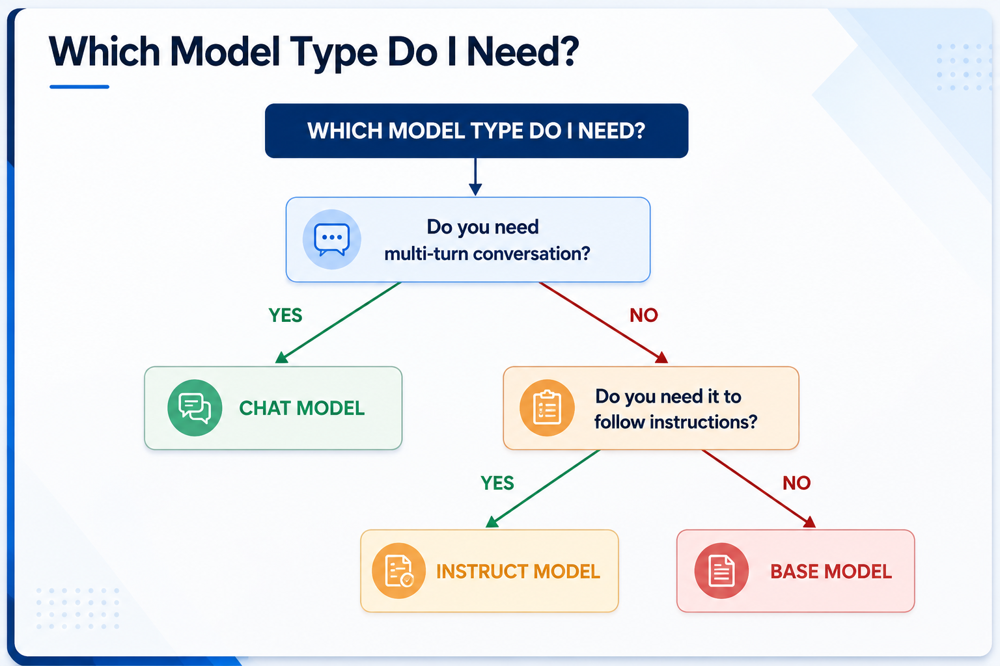

## Part 3: Chat Templates – Comprehensive Guide

### Why Chat Templates Matter

- Each model family uses **different special tokens** to structure conversations.
- Using the wrong template can result in **degraded performance or gibberish output**.
- Hugging Face provides `apply_chat_template()` to handle chat formatting automatically and safely.


```python
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("model-name")

messages = [
    {
        "role": "system",
        "content": "You are helpful."
    },
    {
        "role": "user",
        "content": "Hello!"
    }
]

# Automatically formats for the specific model
formatted = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True
)


### 1. Llama 3.x Chat Template (3.1, 3.2, 3.3)

- **Models:**  
  `meta-llama/Llama-3.1-8B-Instruct`,  
  `meta-llama/Llama-3.2-3B-Instruct`,  
  `meta-llama/Llama-3.3-70B-Instruct`

- **Special Tokens:**
  - `<|begin_of_text|>` — Beginning of sequence (BOS)
  - `<|end_of_text|>` — End of sequence (EOS)
  - `<|start_header_id|>` — Start of role header
  - `<|end_header_id|>` — End of role header
  - `<|eot_id|>` — End of turn
  - `<|eom_id|>` — End of message (used for tool calls)

- **Roles:**  
  `system`, `user`, `assistant`, `ipython` (for tool results)

#### Template Format

```text
<|begin_of_text|><|start_header_id|>system<|end_header_id|>
Cutting Knowledge Date: December 2023
Today Date: {current_date}
{system_message}<|eot_id|>

<|start_header_id|>user<|end_header_id|>
{user_message}<|eot_id|>

<|start_header_id|>assistant<|end_header_id|>
{assistant_response}<|eot_id|>


**Code Example**
```from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("meta-llama/Llama-3.1-8B-Instruct")

messages = [
    {"role": "system", "content": "You are a helpful assistant."},
    {"role": "user", "content": "What is Python?"},
]

formatted = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True
)
print(formatted)```

### 2. DeepSeek V3 / V3.1 Chat Template

- **Models:**  
  `deepseek-ai/DeepSeek-V3`,  
  `deepseek-ai/DeepSeek-V3.1`

- **Special Tokens:**
  - `<｜begin▁of▁sentence｜>` — Beginning of sequence
  - `<｜end▁of▁sentence｜>` — End of sequence
  - `<｜User｜>` — User turn marker
  - `<｜Assistant｜>` — Assistant turn marker
  - `<think>` / `</think>` — Thinking / reasoning blocks (V3.1+)

- **Unique Feature:**  
  Supports both **thinking mode** and **non-thinking mode**

#### Template Format (Non-Thinking Mode)

```text
<｜begin▁of▁sentence｜>{system_prompt}<｜User｜>{query}<｜Assistant｜></think>{response}<｜end▁of▁sentence｜>


In [18]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("deepseek-ai/DeepSeek-V3.1")

messages = [
    {"role": "system", "content": "You are a helpful assistant"},
    {"role": "user", "content": "What is 15 * 23?"},
]

# Non-thinking mode
formatted = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True,
    thinking=False  # Disable thinking mode
)
print(formatted)
# Output: <｜begin▁of▁sentence｜>You are a helpful assistant<｜User｜>What is 15 * 23?<｜Assistant｜></think>

# Thinking mode (for complex reasoning)
formatted_think = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True,
    thinking=True  # Enable thinking mode
)
print(formatted_think)
# Output: <｜begin▁of▁sentence｜>You are a helpful assistant<｜User｜>What is 15 * 23?<｜Assistant｜><think>

config.json:   0%|          | 0.00/1.69k [00:00<?, ?B/s]

`rope_parameters`'s factor field must be a float >= 1, got 40
`rope_parameters`'s beta_fast field must be a float, got 32
`rope_parameters`'s beta_slow field must be a float, got 1


tokenizer_config.json:   0%|          | 0.00/3.74k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.85M [00:00<?, ?B/s]

<｜begin▁of▁sentence｜>You are a helpful assistant<｜User｜>What is 15 * 23?<｜Assistant｜></think>
<｜begin▁of▁sentence｜>You are a helpful assistant<｜User｜>What is 15 * 23?<｜Assistant｜><think>


In [19]:
formatted_think

'<｜begin▁of▁sentence｜>You are a helpful assistant<｜User｜>What is 15 * 23?<｜Assistant｜><think>'

In [20]:
messages = [
    {"role": "system", "content": "You are a helpful assistant"},
    {"role": "user", "content": "Who are you?"},
    {"role": "assistant", "content": "<think>Hmm</think>I am DeepSeek"},
    {"role": "user", "content": "1+1=?"}
]

formatted = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    thinking=True,
    add_generation_prompt=True
)

In [21]:
formatted

'<｜begin▁of▁sentence｜>You are a helpful assistant<｜User｜>Who are you?<｜Assistant｜></think>I am DeepSeek<｜end▁of▁sentence｜><｜User｜>1+1=?<｜Assistant｜><think>'

### 3. Qwen 2.5 / Qwen 3 Chat Template (ChatML-based)

- **Models:**  
  `Qwen/Qwen2.5-72B-Instruct`,  
  `Qwen/Qwen3-8B`,  
  `Qwen/Qwen3-235B-A22B`

- **Special Tokens:**
  - `<|im_start|>` — Start of message
  - `<|im_end|>` — End of message
  - `<think>` / `</think>` — Thinking blocks (Qwen 3)

- **Format:**  
  ChatML (same structure as OpenAI fine-tuning format)

#### Template Format (Qwen 2.5)

```text
<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>

<|im_start|>user
{user_message}<|im_end|>

<|im_start|>assistant
{assistant_response}<|im_end|>


**Code Example**

In [22]:
from transformers import AutoTokenizer

# Qwen 2.5
tokenizer = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-7B-Instruct")

messages = [
    {"role": "system", "content": "You are a helpful assistant."},
    {"role": "user", "content": "Explain quantum computing."},
]

formatted = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True
)
print(formatted)

config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

<|im_start|>system
You are a helpful assistant.<|im_end|>
<|im_start|>user
Explain quantum computing.<|im_end|>
<|im_start|>assistant



### 4. Phi-3 / Phi-3.5 / Phi-4 Chat Template

- **Models:**  
  `microsoft/Phi-3-mini-128k-instruct`,  
  `microsoft/Phi-3.5-mini-instruct`,  
  `microsoft/phi-4`

- **Special Tokens:**
  - `<|system|>` — System role
  - `<|user|>` — User role
  - `<|assistant|>` — Assistant role
  - `<|end|>` — End of turn

- **Supported Languages:**  
  20+ languages including English, Chinese, Japanese, and Korean

#### Template Format

```text
<|system|>
{system_message}<|end|>

<|user|>
{user_message}<|end|>

<|assistant|>
{assistant_response}<|end|>
```

In [23]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("microsoft/Phi-3.5-mini-instruct")

messages = [
    {"role": "system", "content": "You are a helpful AI assistant."},
    {"role": "user", "content": "What is machine learning?"},
]

formatted = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True
)
print(formatted)

config.json:   0%|          | 0.00/3.45k [00:00<?, ?B/s]

This model config has set a `rope_parameters['original_max_position_embeddings']` field, to be used together with `max_position_embeddings` to determine a scaling factor. Please set the `factor` field of `rope_parameters`with this ratio instead -- we recommend the use of this field over `original_max_position_embeddings`, as it is compatible with most model architectures.


tokenizer_config.json:   0%|          | 0.00/3.98k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.84M [00:00<?, ?B/s]

tokenizer.model:   0%|          | 0.00/500k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/306 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

<|system|>
You are a helpful AI assistant.<|end|>
<|user|>
What is machine learning?<|end|>
<|assistant|>



### 5. Gemma 2 / Gemma 3 Chat Template

- **Models:**  
  `google/gemma-2-9b-it`,  
  `google/gemma-2-27b-it`,  
  `google/gemma-3-*`

- **Special Tokens:**
  - `<start_of_turn>` — Start of turn
  - `<end_of_turn>` — End of turn
  - `user` / `model` — Role names (**not** `system`)

- **Important:**  
  Gemma **does not support system messages natively**. Any system-level instructions must be merged into the user prompt.

#### Template Format

```text
<start_of_turn>user
{user_message}<end_of_turn>

<start_of_turn>model
{assistant_response}<end_of_turn>
```

```from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("google/gemma-2-9b-it")

messages = [
    {"role": "user", "content": "Explain neural networks simply."},
]

formatted = tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True
)
print(formatted)
# Output: <start_of_turn>user
# Explain neural networks simply.<end_of_turn>
# <start_of_turn>model```

### Chat Template Comparison Table

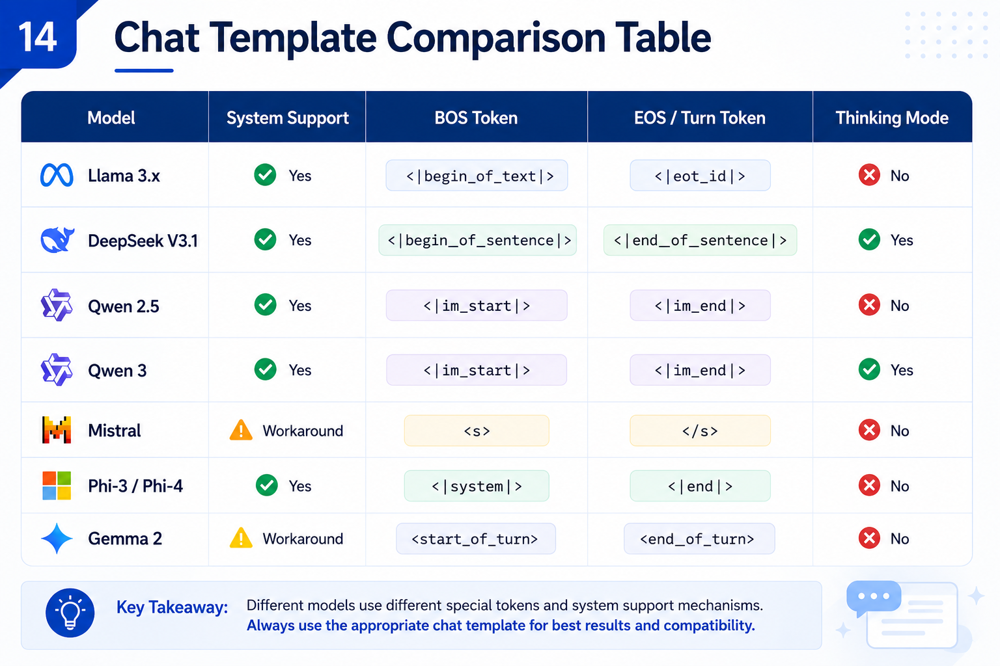

## Part 4: How LLMs Generate Text

### Decoding Strategies in Large Language Models

**Understanding How LLMs Generate Text**

---

## Overview

In this Section, we'll explore the fundamental techniques that Large Language Models (LLMs) use to generate text. While much attention is given to model architectures and training, **decoding strategies** are the critical mechanisms that determine how models select the next token during text generation.

### What We'll Cover:

1. **Background**: How LLMs actually generate text (they don't directly produce words!)
2. **Greedy Search**: The simplest approach - always pick the most likely token
3. **Beam Search**: Consider multiple possibilities simultaneously
4. **Top-k Sampling**: Add randomness by sampling from the k most likely tokens
5. **Nucleus (Top-p) Sampling**: Dynamic sampling based on cumulative probability

### Key Hyperparameters:
- `temperature`: Controls randomness in generation
- `num_beams`: Number of sequences to track in beam search
- `top_k`: Number of top tokens to consider
- `top_p`: Cumulative probability threshold for nucleus sampling

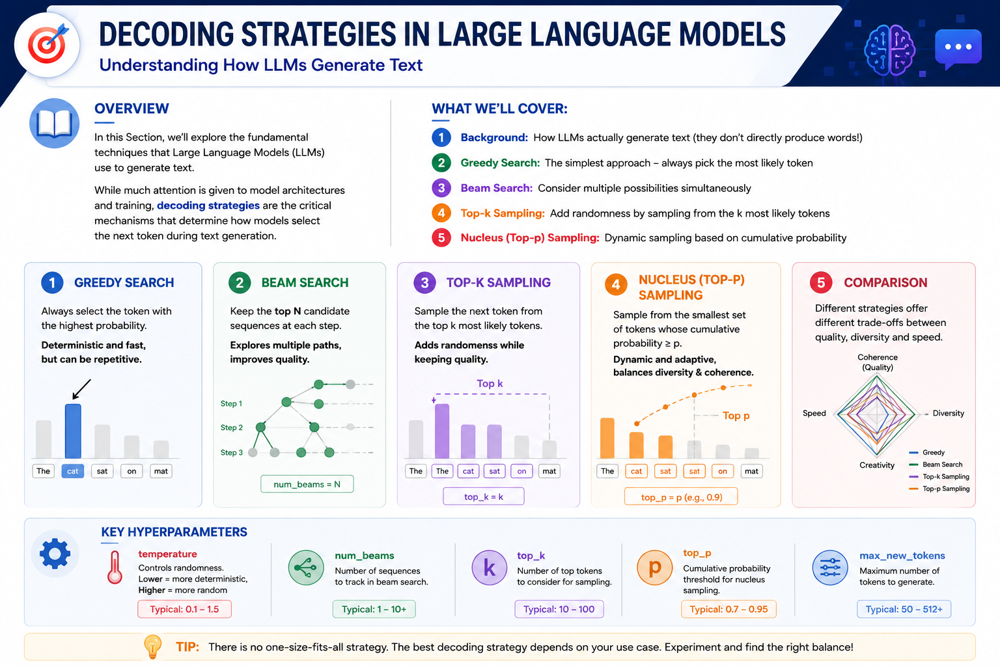

In [24]:
# Install required packages
!pip install transformers torch matplotlib numpy networkx pygraphviz ipywidgets -q
!apt-get install -y graphviz graphviz-dev -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 106.0/106.0 kB 6.2 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 48.6 MB/s eta 0:00:00
  error: subprocess-exited-with-error
  
  × Building wheel for pygraphviz (pyproject.toml) did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  ERROR: Failed building wheel for pygraphviz
ERROR: ERROR: Failed to build installable wheels for some pyproject.toml based projects (pygraphviz)
Reading package lists...
Building dependency tree...
Reading state information...
graphviz is already the newest version (2.42.2-6ubuntu0.1).
The following additional packages will be installed:
  libatk1.0-0 libatk1.0-data libgail-common libgail18 libgtk2.0-0
  libgtk2.0-bin libgtk2.0-common libgvc6-plugi

In [25]:
import torch
from transformers import GPT2LMHeadModel, GPT2Tokenizer
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
import numpy as np
import networkx as nx
import matplotlib.colors as mcolors
from matplotlib.colors import LinearSegmentedColormap
from ipywidgets import interact, FloatSlider, IntSlider

# Set style
plt.style.use('seaborn-v0_8-darkgrid')
np.random.seed(42)
torch.manual_seed(42)

In [26]:
# Load GPT-2 model and tokenizer
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

model = GPT2LMHeadModel.from_pretrained('gpt2').to(device)
tokenizer = GPT2Tokenizer.from_pretrained('gpt2')
model.eval()

print("✅ Model loaded successfully!")

Using device: cuda


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2LMHeadModel LOAD REPORT from: gpt2
Key                  | Status     |  | 
---------------------+------------+--+-
h.{0...11}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


✅ Model loaded successfully!


In [27]:
def animate_probability_distribution(text="I have a dream", num_tokens=50):
    """
    Animate the probability distribution for the next token prediction.
    """
    # Tokenize input
    input_ids = tokenizer.encode(text, return_tensors='pt').to(device)

    # Get model predictions
    with torch.no_grad():
        outputs = model(input_ids)
        logits = outputs.logits[0, -1, :]

    # Get probabilities
    probabilities = torch.nn.functional.softmax(logits, dim=-1)

    # Get top tokens
    top_probs, top_indices = torch.topk(probabilities, num_tokens)
    top_tokens = [tokenizer.decode([idx]) for idx in top_indices.tolist()]

    # Create figure
    fig, ax = plt.subplots(figsize=(14, 6), facecolor='white')

    def animate(frame):
        ax.clear()

        # Show progressively more tokens
        n = min(frame + 1, num_tokens)

        colors = plt.cm.viridis(np.linspace(0, 1, n))
        bars = ax.bar(range(n), top_probs[:n].cpu() * 100, color=colors)

        ax.set_xlabel('Token Rank', fontsize=12, fontweight='bold')
        ax.set_ylabel('Probability (%)', fontsize=12, fontweight='bold')
        ax.set_title(f'Top {n} Token Probabilities for: "{text}"',
                    fontsize=14, fontweight='bold', pad=20)
        ax.set_xticks(range(n))
        ax.set_xticklabels(top_tokens[:n], rotation=45, ha='right')
        ax.grid(True, alpha=0.3, axis='y')

        # Add probability labels on top of bars
        for i, (bar, prob) in enumerate(zip(bars, top_probs[:n])):
            height = bar.get_height()
            if i < 5:  # Only label top 5 for clarity
                ax.text(bar.get_x() + bar.get_width()/2., height,
                       f'{prob.item()*100:.1f}%',
                       ha='center', va='bottom', fontsize=9, fontweight='bold')

        plt.tight_layout()
        return ax,

    anim = FuncAnimation(fig, animate, frames=num_tokens, interval=100, repeat=True)
    plt.close()

    return HTML(anim.to_jshtml())

# Run animation
animate_probability_distribution()

Output hidden; open in https://colab.research.google.com to view.

### Understanding Temperature in Softmax

This section provides an interactive guide to understanding the **temperature parameter** in the softmax function, a crucial concept in machine learning and neural networks.

---

## Table of Contents
1. [Introduction to Softmax](#1-introduction-to-softmax)
2. [The Temperature Parameter](#2-the-temperature-parameter)
3. [Mathematical Intuition](#3-mathematical-intuition)
4. [Visual Demonstrations](#4-visual-demonstrations)
5. [Practical Applications](#5-practical-applications)
6. [Interactive Examples](#6-interactive-examples)

### 1. Introduction to Softmax

The **softmax function** is an activation function commonly used in the output layer of neural networks for multi-class classification problems. It converts a vector of real numbers into a probability distribution.

### Mathematical Definition

For an input vector $\mathbf{z} = [z_1, z_2, ..., z_n]$, the standard softmax function is:

$$
\text{softmax}(z_i) = \frac{e^{z_i}}{\sum_{j=1}^{n} e^{z_j}}
$$

### Key Properties
- **Output range**: Each element is in $[0, 1]$
- **Normalization**: All outputs sum to 1
- **Differentiable**: Enables gradient-based optimization
- **Smooth**: Provides a "soft" version of argmax

In [28]:
# Install required packages (run once)
!pip install -q matplotlib numpy ipywidgets -q

In [29]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
import ipywidgets as widgets
from ipywidgets import interactive

# Set style for better visualizations
plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

In [30]:
def softmax(z, temperature=1.0):
    """
    Compute softmax with temperature parameter.

    Args:
        z: Input array/vector
        temperature: Temperature parameter (T > 0)

    Returns:
        Probability distribution
    """
    z_temp = z / temperature
    exp_z = np.exp(z_temp - np.max(z_temp))  # Numerical stability
    return exp_z / exp_z.sum()

# Example: Standard softmax
logits = np.array([2.0, 1.0, 0.1])
probs = softmax(logits)
print(f"Input logits: {logits}")
print(f"Softmax output: {probs}")
print(f"Sum of probabilities: {probs.sum():.6f}")

Input logits: [2.  1.  0.1]
Softmax output: [0.65900114 0.24243297 0.09856589]
Sum of probabilities: 1.000000


### 2. The Temperature Parameter

The **temperature parameter** $T$ modifies the softmax function to control the "sharpness" of the probability distribution:

$$
\text{softmax}_T(z_i) = \frac{e^{z_i/T}}{\sum_{j=1}^{n} e^{z_j/T}}
$$

### Effects of Temperature

| Temperature | Effect | Use Case |
|-------------|--------|----------|
| $T \to 0$ | **Sharp/Peaked** distribution (approaches hard max) | Confident predictions, exploitation |
| $T = 1$ | **Standard** softmax | Default neural network outputs |
| $T > 1$ | **Smooth/Flat** distribution (more uniform) | Exploration, knowledge distillation |
| $T \to \infty$ | **Uniform** distribution | Maximum uncertainty |

### Intuition

- **Low temperature** ($T < 1$): Makes the model more confident and selective
- **High temperature** ($T > 1$): Makes the model less confident and more exploratory

### 3. Mathematical Intuition

Let's understand how temperature affects the softmax function mathematically:

### Example with Three Classes

Consider logits: $\mathbf{z} = [3.0, 2.0, 1.0]$

**Temperature = 0.5 (Low)**
- Divides logits: $[6.0, 4.0, 2.0]$
- Result: More peaked distribution

**Temperature = 1.0 (Standard)**
- Logits unchanged: $[3.0, 2.0, 1.0]$
- Result: Standard distribution

**Temperature = 2.0 (High)**
- Divides logits: $[1.5, 1.0, 0.5]$
# - Result: More uniform distribution

In [31]:
# Demonstrate temperature effects
logits = np.array([3.0, 2.0, 1.0])
temperatures = [0.5, 1.0, 2.0, 5.0]

print("Effect of Temperature on Probability Distribution\n" + "="*50)
for T in temperatures:
    probs = softmax(logits, temperature=T)
    print(f"\nT = {T:4.1f}: {probs}")
    print(f"         Max prob: {probs.max():.4f}, Entropy: {-np.sum(probs * np.log(probs + 1e-10)):.4f}")

Effect of Temperature on Probability Distribution

T =  0.5: [0.86681333 0.11731043 0.01587624]
         Max prob: 0.8668, Entropy: 0.4411

T =  1.0: [0.66524096 0.24472847 0.09003057]
         Max prob: 0.6652, Entropy: 0.8324

T =  2.0: [0.50648039 0.30719589 0.18632372]
         Max prob: 0.5065, Entropy: 1.0202

T =  5.0: [0.40175958 0.32893292 0.2693075 ]
         Max prob: 0.4018, Entropy: 1.0854


### 4. Visual Demonstrations

Let's visualize how temperature affects the probability distribution.

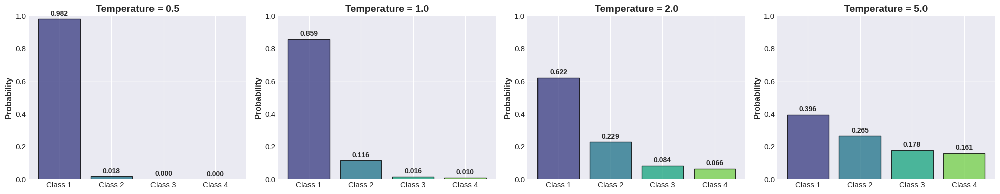


 Observation:
- Low T: Distribution is sharp (high confidence in top class)
- High T: Distribution is smooth (more uncertain, explores more)


In [32]:
def plot_temperature_comparison(logits, temperatures):
    """
    Create a comparison plot showing softmax outputs for different temperatures.
    """
    n_temps = len(temperatures)
    fig, axes = plt.subplots(1, n_temps, figsize=(5*n_temps, 4))

    if n_temps == 1:
        axes = [axes]

    colors = plt.cm.viridis(np.linspace(0.2, 0.8, len(logits)))
    class_names = [f'Class {i+1}' for i in range(len(logits))]

    for idx, T in enumerate(temperatures):
        probs = softmax(logits, temperature=T)

        axes[idx].bar(class_names, probs, color=colors, alpha=0.8, edgecolor='black')
        axes[idx].set_ylim(0, 1)
        axes[idx].set_ylabel('Probability', fontsize=12, fontweight='bold')
        axes[idx].set_title(f'Temperature = {T}', fontsize=14, fontweight='bold')
        axes[idx].grid(axis='y', alpha=0.3)

        # Add probability values on bars
        for i, (prob, class_name) in enumerate(zip(probs, class_names)):
            axes[idx].text(i, prob + 0.02, f'{prob:.3f}',
                          ha='center', fontsize=10, fontweight='bold')

    plt.tight_layout()
    return fig

# Example: Compare different temperatures
logits = np.array([5.0, 3.0, 1.0, 0.5])
temperatures = [0.5, 1.0, 2.0, 5.0]
fig = plot_temperature_comparison(logits, temperatures)
plt.show()

print("\n Observation:")
print("- Low T: Distribution is sharp (high confidence in top class)")
print("- High T: Distribution is smooth (more uncertain, explores more)")

### Animation: Temperature Sweep

In [33]:
def create_temperature_animation(logits, temperature_range=(0.1, 10), n_frames=100):
    """
    Create an animation showing how probabilities change with temperature.
    """
    temperatures = np.linspace(temperature_range[0], temperature_range[1], n_frames)
    class_names = [f'Class {i+1}' for i in range(len(logits))]
    colors = plt.cm.viridis(np.linspace(0.2, 0.8, len(logits)))

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Initialize plots
    probs_init = softmax(logits, temperature=temperatures[0])
    bars = ax1.bar(class_names, probs_init, color=colors, alpha=0.8, edgecolor='black')
    ax1.set_ylim(0, 1)
    ax1.set_ylabel('Probability', fontsize=12, fontweight='bold')
    ax1.set_xlabel('Classes', fontsize=12, fontweight='bold')
    title = ax1.set_title(f'Temperature = {temperatures[0]:.2f}', fontsize=14, fontweight='bold')
    ax1.grid(axis='y', alpha=0.3)

    # Entropy plot
    entropies = []
    line, = ax2.plot([], [], 'b-', linewidth=2)
    ax2.set_xlim(temperature_range[0], temperature_range[1])
    ax2.set_ylim(0, np.log(len(logits)) * 1.1)
    ax2.set_xlabel('Temperature', fontsize=12, fontweight='bold')
    ax2.set_ylabel('Entropy (bits)', fontsize=12, fontweight='bold')
    ax2.set_title('Distribution Entropy vs Temperature', fontsize=14, fontweight='bold')
    ax2.grid(alpha=0.3)
    ax2.axhline(y=np.log(len(logits)), color='r', linestyle='--',
                label='Max Entropy (Uniform)', linewidth=2)
    ax2.legend()

    # Text annotations
    text_objects = []
    for i, bar in enumerate(bars):
        text = ax1.text(i, 0, '', ha='center', fontsize=10, fontweight='bold')
        text_objects.append(text)

    def animate(frame):
        T = temperatures[frame]
        probs = softmax(logits, temperature=T)

        # Update bar heights
        for bar, prob in zip(bars, probs):
            bar.set_height(prob)

        # Update text annotations
        for text, prob in zip(text_objects, probs):
            text.set_text(f'{prob:.3f}')
            text.set_y(prob + 0.02)

        # Update title
        title.set_text(f'Temperature = {T:.2f}')

        # Update entropy plot
        entropy = -np.sum(probs * np.log(probs + 1e-10))
        if frame >= len(entropies):
            entropies.append(entropy)
        line.set_data(temperatures[:len(entropies)], entropies)
        return [*bars, *text_objects, title, line]

    anim = FuncAnimation(fig, animate, frames=n_frames,
                        interval=50, blit=True, repeat=True)
    plt.close(fig)
    return HTML(anim.to_jshtml())

# Create animation
logits = np.array([4.0, 2.5, 1.0, 0.2])
print("🎬 Generating animation... (this may take a moment)")
anim = create_temperature_animation(logits, temperature_range=(0.1, 10), n_frames=80)
display(anim)

Output hidden; open in https://colab.research.google.com to view.

### Application in  Language Model Sampling

In **text generation**, temperature controls creativity vs. determinism:
- **Low T** ($T < 1$): Conservative, predictable text
- **High T** ($T > 1$): Creative, diverse text

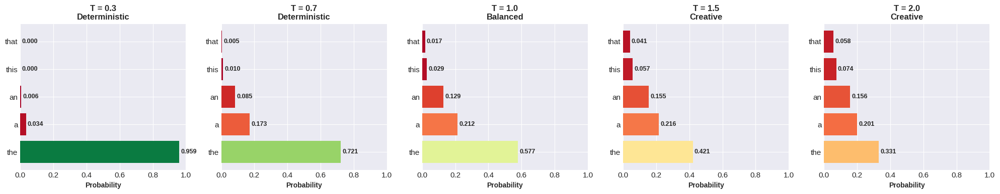


📝 Application:
- T = 0.3: Factual writing, technical docs
- T = 1.0: General purpose text generation
- T = 2.0: Creative writing, brainstorming


In [34]:
def simulate_language_model_sampling():
    """
    Simulate how temperature affects next-token prediction in language models.
    """
    # Simulated logits for next word prediction
    words = ['the', 'a', 'an', 'this', 'that', 'my', 'our', 'his', 'her', 'its']
    logits = np.array([5.0, 4.0, 3.5, 2.0, 1.5, 1.0, 0.8, 0.5, 0.3, 0.1])

    temperatures = [0.3, 0.7, 1.0, 1.5, 2.0]

    fig, axes = plt.subplots(1, len(temperatures), figsize=(20, 4))

    for idx, T in enumerate(temperatures):
        probs = softmax(logits, temperature=T)

        # Plot top 5 words
        top_k = 5
        top_indices = np.argsort(probs)[-top_k:][::-1]

        axes[idx].barh(range(top_k), probs[top_indices],
                      color=plt.cm.RdYlGn(probs[top_indices]))
        axes[idx].set_yticks(range(top_k))
        axes[idx].set_yticklabels([words[i] for i in top_indices])
        axes[idx].set_xlabel('Probability', fontsize=10, fontweight='bold')
        axes[idx].set_title(f'T = {T}\n{"Deterministic" if T < 1 else "Balanced" if T == 1 else "Creative"}',
                           fontsize=12, fontweight='bold')
        axes[idx].set_xlim(0, 1)

        # Add probability labels
        for i, (prob, idx_word) in enumerate(zip(probs[top_indices], top_indices)):
            axes[idx].text(prob + 0.01, i, f'{prob:.3f}',
                          va='center', fontsize=9, fontweight='bold')

    plt.tight_layout()
    plt.show()

    print("\n📝 Application:")
    print("- T = 0.3: Factual writing, technical docs")
    print("- T = 1.0: General purpose text generation")
    print("- T = 2.0: Creative writing, brainstorming")

simulate_language_model_sampling()

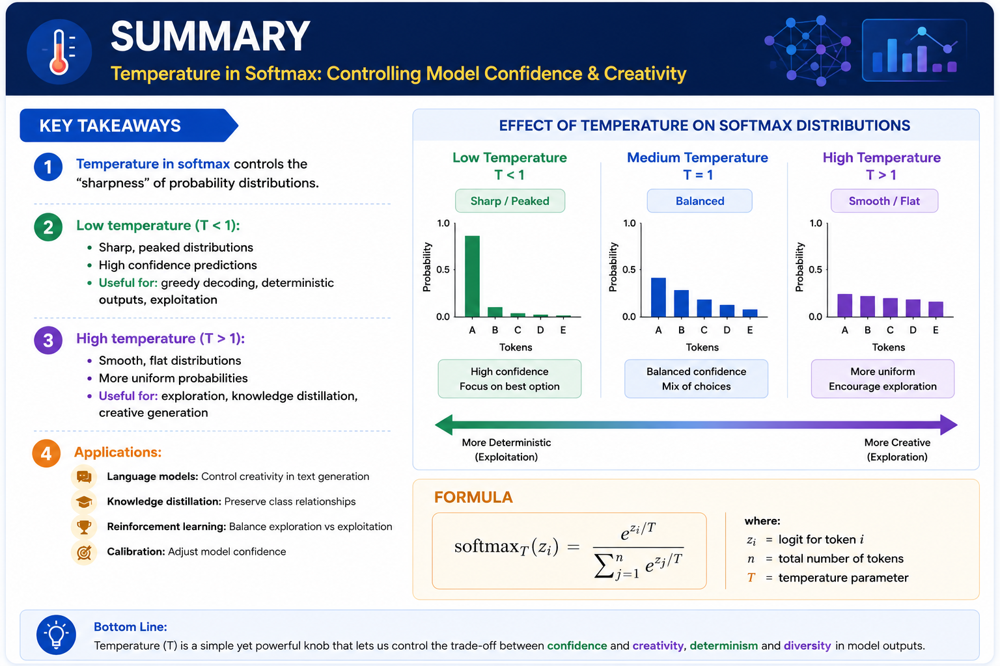

### Further Reading

- [Distilling the Knowledge in a Neural Network](https://arxiv.org/abs/1503.02531) (Hinton et al., 2015)
- [The Curious Case of Neural Text Degeneration](https://arxiv.org/abs/1904.09751) (Holtzman et al., 2019)
- [Calibrating Deep Neural Networks](https://arxiv.org/abs/1706.04599) (Guo et al., 2017)

### Exploring Decoding Strategies

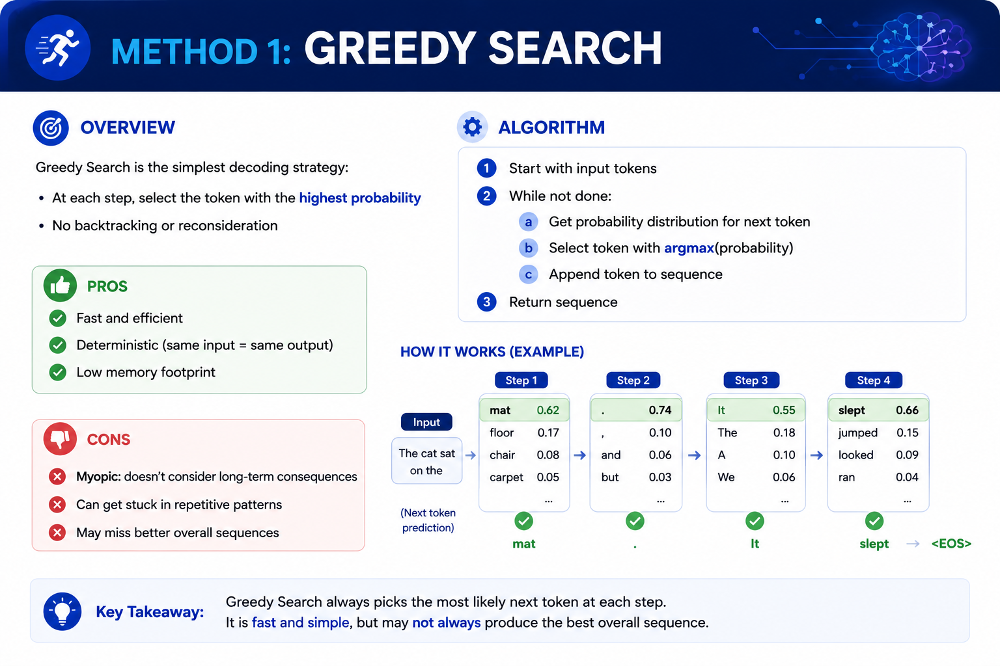

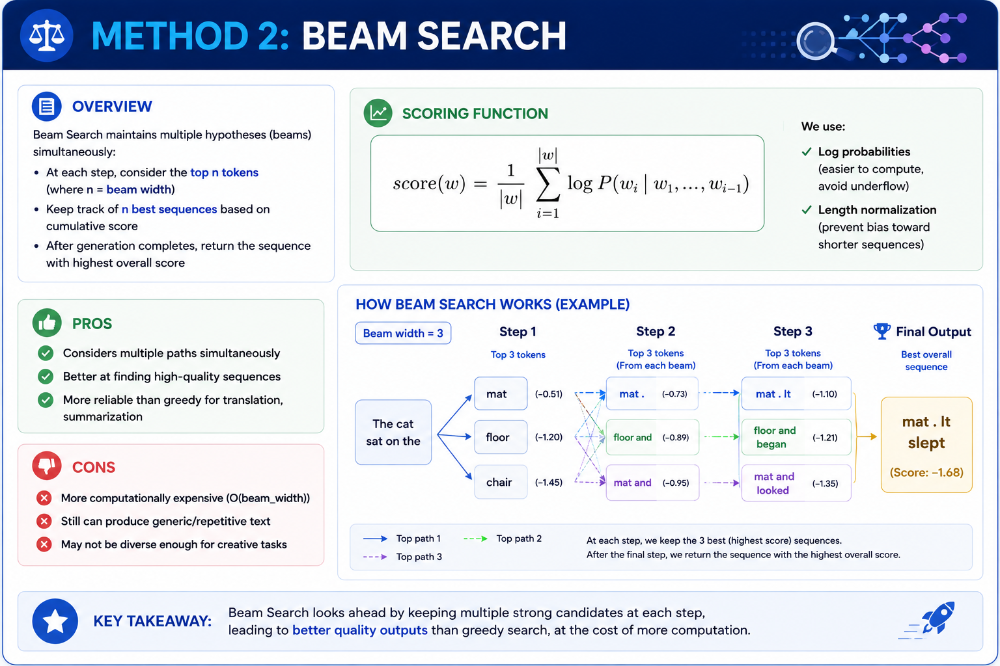

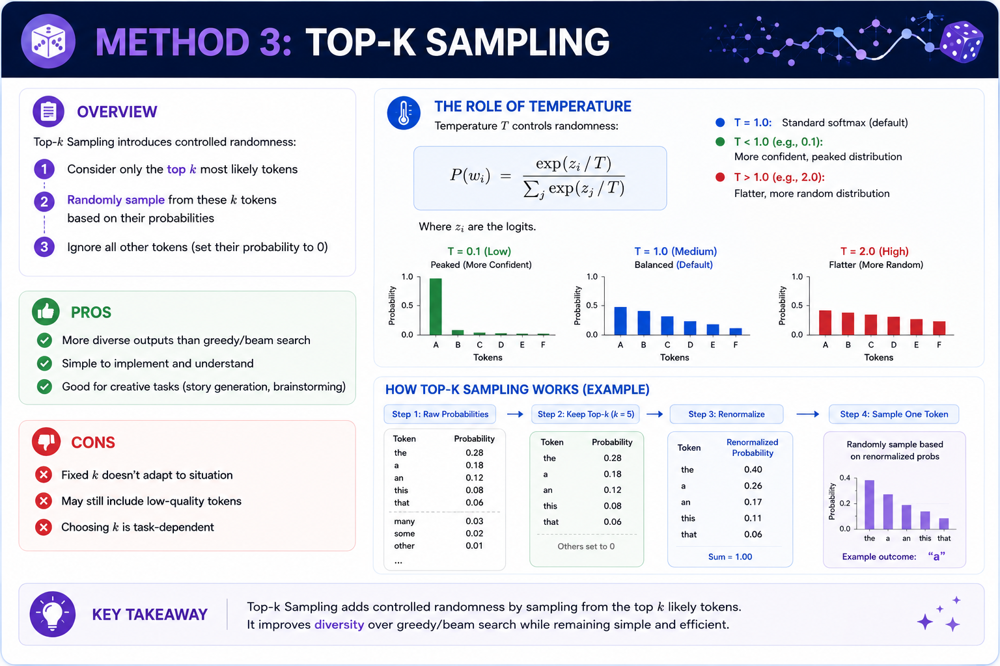

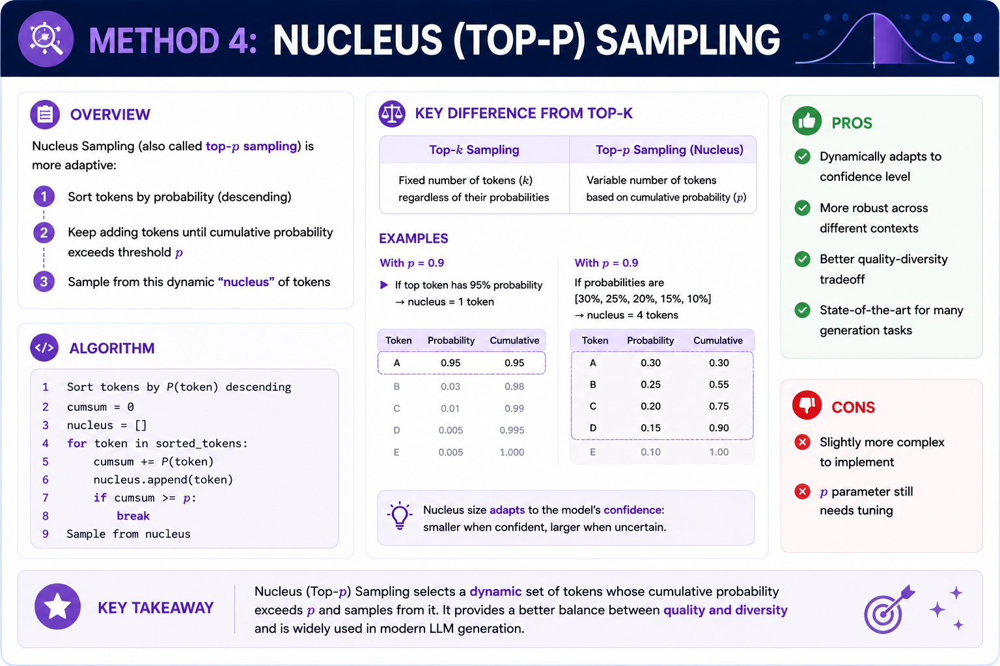

### Summary

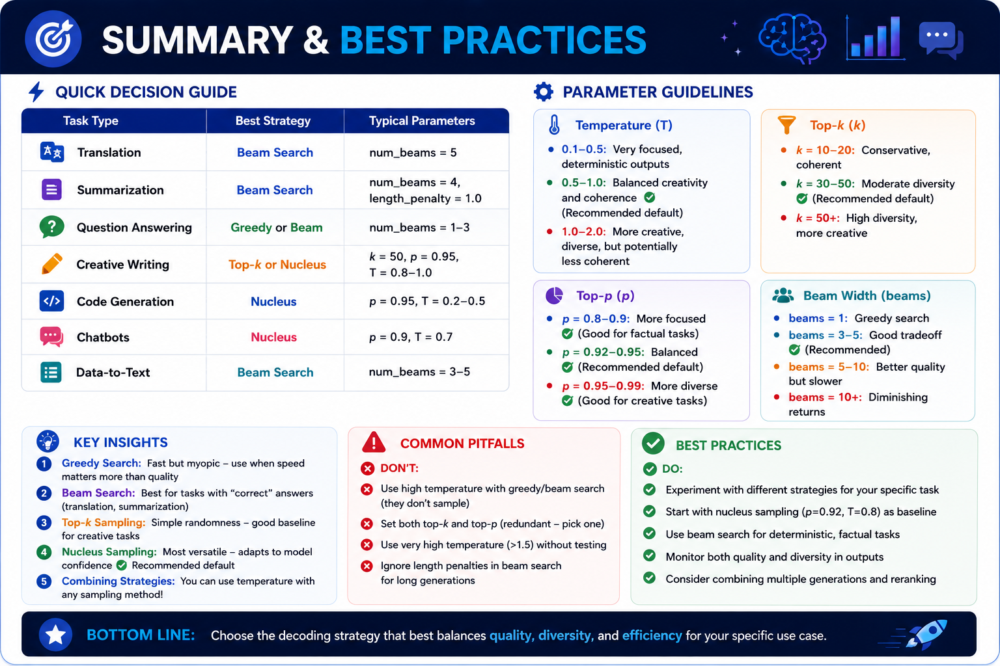

### Illustration using Phi Model

In [35]:
from transformers import AutoModelForCausalLM, AutoTokenizer
import torch

model_name = "microsoft/Phi-3-mini-4k-instruct"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    dtype=torch.float16,
    device_map="auto",
    attn_implementation="eager"
)

config.json:   0%|          | 0.00/967 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/3.44k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.94M [00:00<?, ?B/s]

tokenizer.model:   0%|          | 0.00/500k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/306 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/599 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/16.5k [00:00<?, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/195 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/181 [00:00<?, ?B/s]

In [36]:
# Helper function to generate with chat format
def generate_response(prompt, **gen_kwargs):
    """Generate response using Phi-3 with proper chat template"""
    messages = [{"role": "user", "content": prompt}]

    input_text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )
    inputs = tokenizer(input_text, return_tensors="pt").to(model.device)

    outputs = model.generate(
        **inputs,
        max_new_tokens=100,
        pad_token_id=tokenizer.eos_token_id,
        use_cache=False,
        **gen_kwargs
    )

    # Decode only the new tokens
    response = tokenizer.decode(outputs[0][inputs['input_ids'].shape[1]:], skip_special_tokens=True)
    return response.strip()

#### Greedy Decoding

In [37]:
prompt = "Write a short poem about the ocean."

# Run 3 times to show it's deterministic
for i in range(3):
    response = generate_response(
        prompt,
        do_sample=False  # Greedy - no sampling
    )
    print(f"Run {i+1}: {response[:150]}...")
    print("-"*50)
    print("-"*50)

Run 1: Whispers of the ocean's breath,

A symphony of waves, a dance with death.

Azure depths, a mystery untold,

In its embrace, the world's heart unfolds....
--------------------------------------------------
--------------------------------------------------
Run 2: Whispers of the ocean's breath,

A symphony of waves, a dance with death.

Azure depths, a mystery untold,

In its embrace, the world's heart unfolds....
--------------------------------------------------
--------------------------------------------------
Run 3: Whispers of the ocean's breath,

A symphony of waves, a dance with death.

Azure depths, a mystery untold,

In its embrace, the world's heart unfolds....
--------------------------------------------------
--------------------------------------------------


#### Temperature Compare

In [38]:
prompt = "Give me 3 creative names for a coffee shop."
temperatures = [0.1, 0.5, 0.7, 1.0, 1.5]

for temp in temperatures:
    response = generate_response(
        prompt,
        do_sample=True,
        temperature=temp,
        top_p=1.0,  # Disable top_p to isolate temperature effect
        top_k=0     # Disable top_k
    )
    print(f"🌡️ Temperature = {temp}: {response[:200]}")
    print("-"*50)
    print("-"*50)

🌡️ Temperature = 0.1: 1. Brewed Awakenings
2. The Grind & Grind
3. Java Jive
--------------------------------------------------
--------------------------------------------------
🌡️ Temperature = 0.5: 1. Aroma Haven: A cozy and inviting coffee shop that offers a sanctuary from the hustle and bustle of daily life.

2. Beans & Brews: A trendy and modern coffee shop that specializes in high-quality, a
--------------------------------------------------
--------------------------------------------------
🌡️ Temperature = 0.7: 1. Java Jive Junction

2. Brewed Beans Bistro

3. Espresso Emporium
--------------------------------------------------
--------------------------------------------------
🌡️ Temperature = 1.0: 1. "Caffé Creativé"  

2. "The Grounded Hub"  

3. "BrewArt Café"
--------------------------------------------------
--------------------------------------------------
🌡️ Temperature = 1.5: 1) Brewed Loyalty.
2) Java Quip, concept named after character Mackenna in Nevada fail Payne

#### Top-K Sampling

In [39]:
prompt = "The best programming language is"
top_k_values = [1, 5, 10, 50, 100]

for k in top_k_values:
    for run in range(2):  # 2 runs to show variation
        response = generate_response(
            prompt,
            do_sample=True,
            top_k=k,
            temperature=0.8,
            top_p=1.0  # Disable top_p to isolate top_k effect
        )
        print(f"🎯 top_k={k}, Run {run+1}: {response[:100]}...")
        print("-"*50)
        print("-"*50)

🎯 top_k=1, Run 1: The question of which programming language is the "best" is subjective and depends on various factor...
--------------------------------------------------
--------------------------------------------------
🎯 top_k=1, Run 2: The question of which programming language is the "best" is subjective and depends on various factor...
--------------------------------------------------
--------------------------------------------------
🎯 top_k=5, Run 1: Determining the "best" programming language is highly subjective and depends on various factors such...
--------------------------------------------------
--------------------------------------------------
🎯 top_k=5, Run 2: Determining the "best" programming language is subjective and varies depending on the context. Here ...
--------------------------------------------------
--------------------------------------------------
🎯 top_k=10, Run 1: Determining the best programming language is highly subjective and depends on various

#### Top-p(Nucleus) Sampling

In [ ]:
prompt = "A good weekend activity is"
top_p_values = [0.1, 0.5, 0.9, 0.95, 1.0]

for p in top_p_values:
    for run in range(2):
        response = generate_response(
            prompt,
            do_sample=True,
            top_p=p,
            temperature=0.8,
            top_k=0  # Disable top_k to isolate top_p effect
        )
        print(f"🎲 top_p={p}, Run {run+1}: {response[:100]}...")
        print("-"*50)
        print("-"*50)

#### Beam Search

In [ ]:
prompt = "Translate to French: The weather is beautiful today."
beam_values = [1, 2, 4, 6]

for num_beams in beam_values:
    response = generate_response(
        prompt,
        do_sample=False,  # Beam search doesn't use sampling
        num_beams=num_beams,
        early_stopping=True
    )
    print(f"🔍 num_beams={num_beams}: {response[:150]}")
    print("-"*50)
    print("-"*50)

#### Repetition Penalty

In [ ]:
prompt = "List things you can do at a park:"
penalties = [1.0, 1.1, 1.2, 1.5]

for penalty in penalties:
    response = generate_response(
        prompt,
        do_sample=True,
        temperature=0.8,
        top_p=0.9,
        repetition_penalty=penalty,
    )
    print(f"🔄 repetition_penalty={penalty}: {response[:200]}...")
    print("-"*50)
    print("-"*50)

## Part 5: OpenAI Chat Completions API Basics

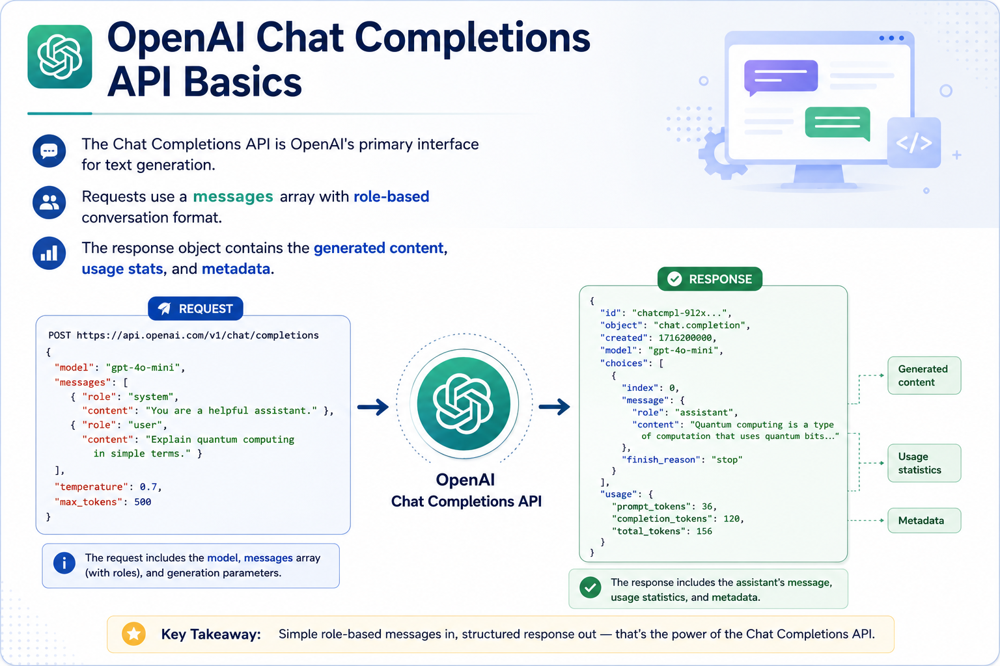

In [ ]:
from openai import OpenAI

client = OpenAI()

# Minimal working example
response = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[
        {"role": "user", "content": "What is the capital of France?"}
    ]
)

print(response.choices[0].message.content)


**Output:**

```
The capital of France is Paris.
```

* The response object structure:
  
* `response.id`- Unique request identifier
  
* `response.choices[0].message.content`- Generated text
  
* `response.choices[0].finish_reason`- Why generation stopped (`stop`, `length`, `tool_calls`)
  
* `response.usage`- Token counts (prompt, completion, total)
---

## What This Output Represents

This object is a **model response choice** returned by a Chat Completions API call.  
It represents **one completed answer** generated by the assistant.

---

## Overall Structure

```text
[
  Choice(
    finish_reason='stop',
    index=0,
    logprobs=None,
    message=ChatCompletionMessage(...)
  )
]


In [ ]:
print(response.choices)

### 3. Message Roles

- Messages use four distinct roles to structure conversations.
- Each role serves a specific purpose in guiding model behavior.

| Role        | Purpose                                   | Best Practice                                  |
|-------------|--------------------------------------------|-----------------------------------------------|
| `system`    | Sets AI behavior, personality, constraints | Place first; define output format              |
| `user`      | Human/end-user messages                    | Contains queries and context                  |
| `assistant` | Model's previous responses                 | Include for multi-turn context                |
| `tool`      | Function/tool responses                   | Return results with `tool_call_id`             |


#### Multi-Turn Conversation

In [ ]:
# Multi-turn conversation example
messages = [
    {
        "role": "system",
        "content": """You are a Python expert. Follow these rules:
        1. Provide concise, working code
        2. Include type hints
        3. Add brief inline comments"""
    },
    {
        "role": "user",
        "content": "Write a function to calculate factorial"
    },
    {
        "role": "assistant",
        "content": """```python
def factorial(n: int) -> int:
    if n <= 1:
        return 1
    return n * factorial(n - 1)
```"""
    },
    {
        "role": "user",
        "content": "Now add memoization to optimize it"
    }
]

In [ ]:
response = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=messages
)

print(response.choices[0].message.content)

**Output:**
```python
from functools import lru_cache

@lru_cache(maxsize=None)
def factorial(n: int) -> int:
    # Handle base case with memoization for O(1) repeated calls
    if n <= 1:
        return 1
    return n * factorial(n - 1)
```

---

### 4. API Parameters Deep Dive

* Parameters control generation behavior, randomness, and output format.
* Understanding these enables fine-tuned control over model responses.

#### Core Parameters

| Parameter | Description | Default |
|-----------|-------------|---------|
| `model` | Model identifier (e.g., `gpt-4o`, `gpt-4o-mini`) | Required |
| `messages` | Conversation messages array | Required |
| `max_completion_tokens` | Maximum tokens to generate | Model default |
| `temperature` | Randomness: 0=deterministic, 2=creative | 1.0 |
| `top_p` | Nucleus sampling: consider top N% probability | 1.0 |
| `presence_penalty` | -2 to 2: penalize new topics | 0 |
| `frequency_penalty` | -2 to 2: penalize repeated tokens | 0 |
| `stop` | Stop sequences (up to 4) | None |
| `seed` | For reproducible outputs (best effort) | None |

In [ ]:
# Deterministic output (code generation, factual queries)
response = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[{"role": "user", "content": "Write a SQL query to select all users"}],
    temperature=0,  # Most deterministic
)

In [ ]:
# Creative output (storytelling, brainstorming)
response = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[{"role": "user", "content": "Write a creative haiku about coding"}],
    temperature=1.5,  # More creative
)

* **Temperature vs Top_p**: OpenAI recommends modifying only one, not both.
* **Presence penalty**: Encourages topic diversity (positive values).
* **Frequency penalty**: Reduces verbatim repetition (positive values).

---

###  Streaming Responses [POST READ]

* Streaming delivers responses token-by-token for real-time UIs.
* Reduces perceived latency from seconds to milliseconds.
* Enabled by setting `stream=True` in the API call.

In [ ]:
stream = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[{"role": "user", "content": "Explain machine learning in 3 sentences."}],
    stream=True
)

# Process tokens as they arrive
print("Response: ", end="")
for chunk in stream:
    if chunk.choices[0].delta.content is not None:
        print(chunk.choices[0].delta.content, end="", flush=True)
print()

###  Structured Output using Pydantic [POST READ]

In [ ]:
from pydantic import BaseModel
from typing import List

class MovieReview(BaseModel):
    title: str
    rating: float
    pros: List[str]
    cons: List[str]

completion = client.beta.chat.completions.parse(
    model="gpt-4o-2024-08-06",
    messages=[{"role": "user", "content": "Review The Matrix"}],
    response_format=MovieReview
)

result = completion.choices[0].message.parsed
print(f"{result.title}: {result.rating}/10")

###  Function Calling

In [ ]:
import json

tools = [{
    "type": "function",
    "function": {
        "name": "get_weather",
        "description": "Get weather for a city",
        "parameters": {
            "type": "object",
            "properties": {
                "city": {"type": "string"},
                "unit": {"type": "string", "enum": ["celsius", "fahrenheit"]}
            },
            "required": ["city"]
        }
    }
}]

response = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[{"role": "user", "content": "Weather in Paris?"}],
    tools=tools
)

if response.choices[0].message.tool_calls:
    tool_call = response.choices[0].message.tool_calls[0]
    args = json.loads(tool_call.function.arguments)
    print(f"Call {tool_call.function.name} with {args}")